# Tuần 1: Ôn Tập Hồi Quy Tuyến Tính & Gradient Descent
*(Supervised Machine Learning: Linear Regression & Gradient Descent)*

> **Nguồn tài liệu tham khảo cốt lõi:**
> - Slide bài giảng: `MLS_C1_PDFs/C1_W1.pdf` (GS. Andrew Ng - DeepLearning.AI / Stanford)
> - Các bài thực hành chuẩn: `C1_W1_Lab03`, `C1_W1_Lab04`, `C1_W1_Lab05`

---
## 🎯 Mục tiêu ôn tập nhanh:
1. **Mô hình Hồi quy tuyến tính đơn biến (Linear Regression with one variable):** $f_{w,b}(x) = wx + b$
2. **Hàm chi phí (Cost Function $J(w,b)$):** Đo lường mức độ sai lệch bằng Sai số bình phương trung bình (MSE) và trực quan hóa mặt cong hình lòng chảo 3D (*Soup Bowl*).
3. **Thuật toán Gradient Descent:** Tự động điều chỉnh trọng số $(w, b)$ theo hướng dốc để tối thiểu hóa hàm chi phí.
4. **Thực hành chạy code:** Tự tay viết hàm tính đạo hàm, chạy vòng lặp cập nhật và quan sát đường khớp tối ưu.

---
## 1. Khởi tạo Thư viện & Cấu hình Đồ thị

In [1]:
import math, copy
import numpy as np
import matplotlib.pyplot as plt

# Áp dụng style vẽ đồ thị chuẩn của khóa học Andrew Ng
plt.style.use('./deeplearning.mplstyle')

# Nhập các hàm trực quan hóa tương tác 3D và contour từ lab_utils_uni
from lab_utils_uni import plt_intuition, plt_stationary, plt_update_onclick, soup_bowl
from lab_utils_uni import plt_house_x, plt_contour_wgrad, plt_divergence, plt_gradients
from lab_utils_common import dlc

print('✓ Đã nạp thành công các thư viện và công cụ vẽ đồ thị!')

✓ Đã nạp thành công các thư viện và công cụ vẽ đồ thị!


---
## 2. Dữ liệu Huấn Luyện & Mô Hình Hồi Quy Tuyến Tính

Giả sử ta có dữ liệu gồm:
- $x$ (Feature / Đặc trưng đầu vào): Diện tích nhà (đơn vị: $1000\text{ sqft}$) hoặc Số giờ bật điều hòa.
- $y$ (Target / Nhãn mục tiêu): Giá nhà (đơn vị: $1000\text{ USD}$) hoặc Tiền điện.

Ký hiệu chuẩn theo bài giảng của thầy Andrew Ng:
- $m$: Số lượng mẫu dữ liệu (training examples).
- $(x^{(i)}, y^{(i)})$: Mẫu dữ liệu thứ $i$.
- $f_{w,b}(x) = w \cdot x + b$: Hàm dự đoán (Hypothesis/Model).

Dữ liệu x_train = [1. 2.]
Dữ liệu y_train = [300. 500.]
Số lượng mẫu dữ liệu m = 2


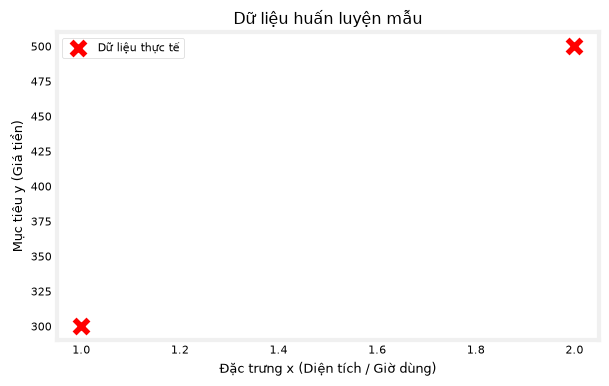

In [2]:
# Dữ liệu huấn luyện mẫu (2 điểm dữ liệu)
x_train = np.array([1.0, 2.0])
y_train = np.array([300.0, 500.0])
m = x_train.shape[0]

print(f'Dữ liệu x_train = {x_train}')
print(f'Dữ liệu y_train = {y_train}')
print(f'Số lượng mẫu dữ liệu m = {m}')

# Vẽ biểu đồ phân tán các điểm dữ liệu thực tế
plt.figure(figsize=(7, 4))
plt.scatter(x_train, y_train, marker='x', c='r', s=100, label='Dữ liệu thực tế')
plt.title('Dữ liệu huấn luyện mẫu')
plt.xlabel('Đặc trưng x (Diện tích / Giờ dùng)')
plt.ylabel('Mục tiêu y (Giá tiền)')
plt.legend()
plt.show()

---
## 3. Hàm Chi Phí (Cost Function $J(w,b)$)

Hàm chi phí đo lường mức độ sai lệch giữa giá trị dự đoán $\hat{y}^{(i)} = f_{w,b}(x^{(i)})$ và giá trị thực tế $y^{(i)}$.

Công thức **Sai số bình phương trung bình (Mean Squared Error - MSE)**:
$$J(w,b) = \frac{1}{2m} \sum_{i=0}^{m-1} \left( f_{w,b}(x^{(i)}) - y^{(i)} \right)^2$$

*(Ghi chú: Thầy Andrew Ng nhân thêm $\frac{1}{2}$ để khi lấy đạo hàm, số mũ $2$ triệt tiêu với $\frac{1}{2}$, giúp công thức đạo hàm đẹp và gọn gàng hơn).*

Mục tiêu của Machine Learning: **Tìm bộ số $(w, b)$ sao cho $J(w, b)$ đạt giá trị nhỏ nhất!**

In [3]:
def compute_cost(x, y, w, b):
    """
    Tính toán hàm chi phí J(w, b) cho hồi quy tuyến tính.
    Args:
      x (ndarray (m,)): Dữ liệu đầu vào, m mẫu
      y (ndarray (m,)): Nhãn thực tế, m mẫu
      w, b (scalar)   : Các tham số của mô hình
    Returns:
      total_cost (float): Giá trị chi phí J(w, b)
    """
    m = x.shape[0]
    cost_sum = 0.0
    for i in range(m):
        f_wb = w * x[i] + b
        cost = (f_wb - y[i]) ** 2
        cost_sum += cost
    total_cost = (1 / (2 * m)) * cost_sum
    return total_cost

# Thử tính chi phí với vài giá trị w, b khác nhau:
print(f'Chi phí khi w=100, b=100 : {compute_cost(x_train, y_train, 100, 100):.2f}')
print(f'Chi phí khi w=200, b=100 (khớp chuẩn): {compute_cost(x_train, y_train, 200, 100):.2f}')

Chi phí khi w=100, b=100 : 12500.00
Chi phí khi w=200, b=100 (khớp chuẩn): 0.00


### 3.1. Trực quan hóa Hình học của Hàm Chi Phí
- **Khi chỉ có 1 tham số $w$ (cố định $b=0$):** Đồ thị $J(w)$ là một đường cong Parabol hình chữ U.
- **Khi có cả 2 tham số $(w, b)$:** Đồ thị $J(w, b)$ là một **mặt cong hình lòng chảo 3D (*Soup Bowl*)** hoặc các đường đồng mức (*Contour Plot*).

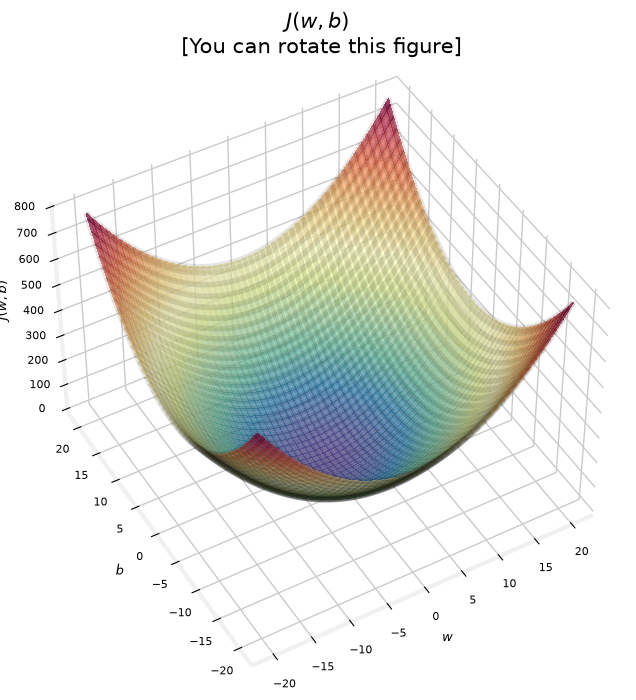

In [4]:
# Trực quan hóa mặt cong lòng chảo 3D (Soup Bowl) của Hàm Cost Function
soup_bowl()

---
## 4. Thuật Toán Hạ Độ Dốc (Gradient Descent)

Thay vì kéo thanh trượt bằng tay để mò đáy lòng chảo, **Gradient Descent** là thuật toán tự động di chuyển dần dần theo hướng dốc xuống để tìm đáy.

<figure>
  <center><img src="./images/C1_W1_L4_S1_Lecture_GD.png" style="width:700px;"></center>
</figure>

### 4.1. Công thức cập nhật đồng thời (Simultaneous Update):
$$\begin{aligned}
w &= w - \alpha \frac{\partial J(w,b)}{\partial w} \\
b &= b - \alpha \frac{\partial J(w,b)}{\partial b}
\end{aligned}$$

Trong đó:
- $\alpha$ (Alpha - Learning Rate / Tốc độ học): Độ lớn của mỗi bước nhảy.
- $\frac{\partial J}{\partial w}, \frac{\partial J}{\partial b}$: Đạo hàm riêng (đo độ dốc). Khi sườn dốc nghiêng âm, đạo hàm mang dấu âm $\rightarrow$ trừ đi số âm thành cộng (tăng $w$). Khi sườn dốc dương, trừ đi số dương thành giảm $w$. Quả bóng luôn lăn xuôi về đáy!

### 4.2. Công thức đạo hàm cụ thể cho Hồi quy tuyến tính:
$$\frac{\partial J(w,b)}{\partial w} = \frac{1}{m} \sum_{i=0}^{m-1} \left( f_{w,b}(x^{(i)}) - y^{(i)} \right) x^{(i)}$$
$$\frac{\partial J(w,b)}{\partial b} = \frac{1}{m} \sum_{i=0}^{m-1} \left( f_{w,b}(x^{(i)}) - y^{(i)} \right)$$

### 🎮 Bảng Điều Khiển Tương Tác: Quả Bóng Lăn Dốc
*(Không cần gõ code! Bạn chỉ cần kéo thanh trượt hoặc bấm nút bên dưới để quan sát trực tiếp)*

In [5]:
from IPython.display import IFrame
IFrame(src="demo_gradient_descent.html", width=740, height=480)

### 4.3. Cài đặt hàm tính Đạo hàm (`compute_gradient`)

In [6]:
def compute_gradient(x, y, w, b):
    """
    Tính toán đạo hàm riêng dj_dw và dj_db cho hồi quy tuyến tính.
    """
    m = x.shape[0]
    dj_dw = 0.0
    dj_db = 0.0

    for i in range(m):
        f_wb = w * x[i] + b
        dj_dw_i = (f_wb - y[i]) * x[i]
        dj_db_i = f_wb - y[i]
        dj_dw += dj_dw_i
        dj_db += dj_db_i

    dj_dw = dj_dw / m
    dj_db = dj_db / m
    return dj_dw, dj_db

# Thử tính gradient tại điểm khởi đầu (w=0, b=0)
tmp_dj_dw, tmp_dj_db = compute_gradient(x_train, y_train, 0, 0)
print(f'Tại w=0, b=0 -> dj_dw = {tmp_dj_dw:.2f}, dj_db = {tmp_dj_db:.2f}')

Tại w=0, b=0 -> dj_dw = -650.00, dj_db = -400.00


### 4.4. Cài đặt toàn bộ Thuật toán Gradient Descent (`gradient_descent`)

In [7]:
def gradient_descent(x, y, w_in, b_in, alpha, num_iters, cost_function, gradient_function):
    """
    Thực hiện thuật toán hạ độ dốc để tìm w, b tối ưu.
    """
    w = copy.deepcopy(w_in)
    b = b_in
    J_history = []
    p_history = []

    for i in range(num_iters):
        # 1. Tính gradient hiện tại
        dj_dw, dj_db = gradient_function(x, y, w, b)

        # 2. Cập nhật đồng thời w và b theo tốc độ học alpha
        w = w - alpha * dj_dw
        b = b - alpha * dj_db

        # 3. Lưu lịch sử chi phí
        if i < 100000:
            cost = cost_function(x, y, w, b)
            J_history.append(cost)
            p_history.append([w, b])

        # In tiến trình mỗi 10% tổng số vòng lặp
        if i % math.ceil(num_iters / 10) == 0:
            print(f'Vòng lặp {i:4d}: Chi phí J = {J_history[-1]:0.2e} | dj_dw: {dj_dw: 0.3e}, dj_db: {dj_db: 0.3e} | w: {w: 0.3e}, b: {b: 0.5e}')

    return w, b, J_history, p_history

---
## 5. Chạy Thử Nghiệm & Đánh Giá Kết Quả

Bây giờ, ta khởi tạo $w=0, b=0$ và cho máy tính tự động tìm kiếm nghiệm tối ưu:

In [8]:
# Thiết lập tham số ban đầu
w_init = 0.0
b_init = 0.0
iterations = 10000
tmp_alpha = 1.0e-2  # alpha = 0.01

# Chạy gradient descent
w_final, b_final, J_hist, p_hist = gradient_descent(
    x_train, y_train, w_init, b_init, tmp_alpha, iterations, compute_cost, compute_gradient
)

print(f'\n===> Kết quả tối ưu tìm được: w = {w_final:0.4f}, b = {b_final:0.4f}')

Vòng lặp    0: Chi phí J = 7.93e+04 | dj_dw: -6.500e+02, dj_db: -4.000e+02 | w:  6.500e+00, b:  4.00000e+00
Vòng lặp 1000: Chi phí J = 3.41e+00 | dj_dw: -3.712e-01, dj_db:  6.007e-01 | w:  1.949e+02, b:  1.08228e+02
Vòng lặp 2000: Chi phí J = 7.93e-01 | dj_dw: -1.789e-01, dj_db:  2.895e-01 | w:  1.975e+02, b:  1.03966e+02
Vòng lặp 3000: Chi phí J = 1.84e-01 | dj_dw: -8.625e-02, dj_db:  1.396e-01 | w:  1.988e+02, b:  1.01912e+02
Vòng lặp 4000: Chi phí J = 4.28e-02 | dj_dw: -4.158e-02, dj_db:  6.727e-02 | w:  1.994e+02, b:  1.00922e+02
Vòng lặp 5000: Chi phí J = 9.95e-03 | dj_dw: -2.004e-02, dj_db:  3.243e-02 | w:  1.997e+02, b:  1.00444e+02
Vòng lặp 6000: Chi phí J = 2.31e-03 | dj_dw: -9.660e-03, dj_db:  1.563e-02 | w:  1.999e+02, b:  1.00214e+02
Vòng lặp 7000: Chi phí J = 5.37e-04 | dj_dw: -4.657e-03, dj_db:  7.535e-03 | w:  1.999e+02, b:  1.00103e+02
Vòng lặp 8000: Chi phí J = 1.25e-04 | dj_dw: -2.245e-03, dj_db:  3.632e-03 | w:  2.000e+02, b:  1.00050e+02
Vòng lặp 9000: Chi phí J = 2

### 5.1. Quan sát Chi phí (Cost) giảm dần theo từng Vòng lặp
Đồ thị này là dấu hiệu chuẩn để kiểm tra xem thuật toán có đang **hội tụ (converge)** về đáy thung lũng hay không:

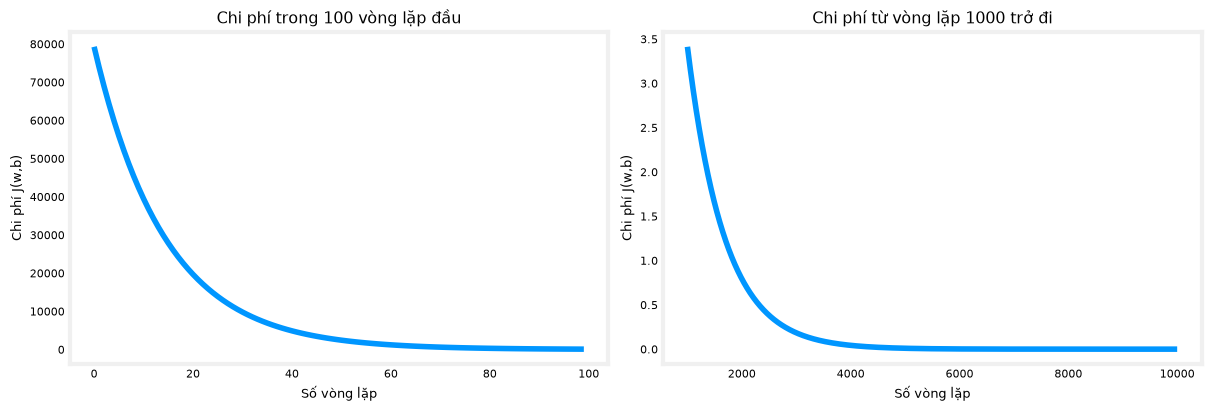

In [9]:
fig, (ax1, ax2) = plt.subplots(1, 2, constrained_layout=True, figsize=(12, 4))
ax1.plot(J_hist[:100])
ax2.plot(1000 + np.arange(len(J_hist[1000:])), J_hist[1000:])
ax1.set_title('Chi phí trong 100 vòng lặp đầu')
ax2.set_title('Chi phí từ vòng lặp 1000 trở đi')
ax1.set_ylabel('Chi phí J(w,b)')
ax2.set_ylabel('Chi phí J(w,b)')
ax1.set_xlabel('Số vòng lặp')
ax2.set_xlabel('Số vòng lặp')
plt.show()

### 5.2. Vẽ Đường Dự Đoán Tối Ưu đi qua Dữ Liệu Thực Tế

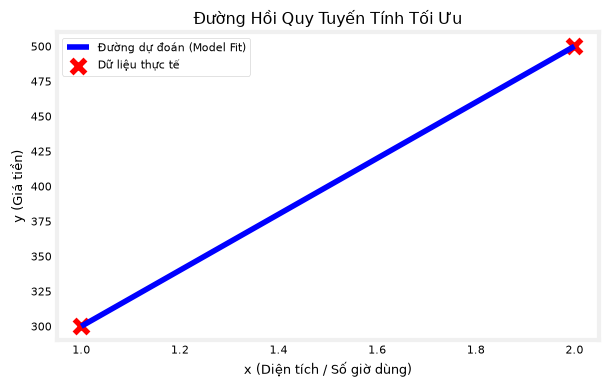

In [10]:
# Tính các giá trị dự đoán từ bộ w_final, b_final
m = x_train.shape[0]
predicted = np.zeros(m)
for i in range(m):
    predicted[i] = w_final * x_train[i] + b_final

# Vẽ đồ thị so sánh
plt.figure(figsize=(7, 4))
plt.plot(x_train, predicted, c='b', label='Đường dự đoán (Model Fit)')
plt.scatter(x_train, y_train, marker='x', c='r', s=100, label='Dữ liệu thực tế')
plt.title('Đường Hồi Quy Tuyến Tính Tối Ưu')
plt.xlabel('x (Diện tích / Số giờ dùng)')
plt.ylabel('y (Giá tiền)')
plt.legend()
plt.show()

### 5.3. Trực quan hóa Đường đi của Quả bóng trên Đồ thị Đường bao (Contour Plot)
Đồ thị dưới đây thể hiện chính xác cách quả bóng xuất phát từ điểm bất kỳ và men theo các đường đồng mức rơi thẳng vào tâm vòng tròn nhỏ nhất (đáy thung lũng):

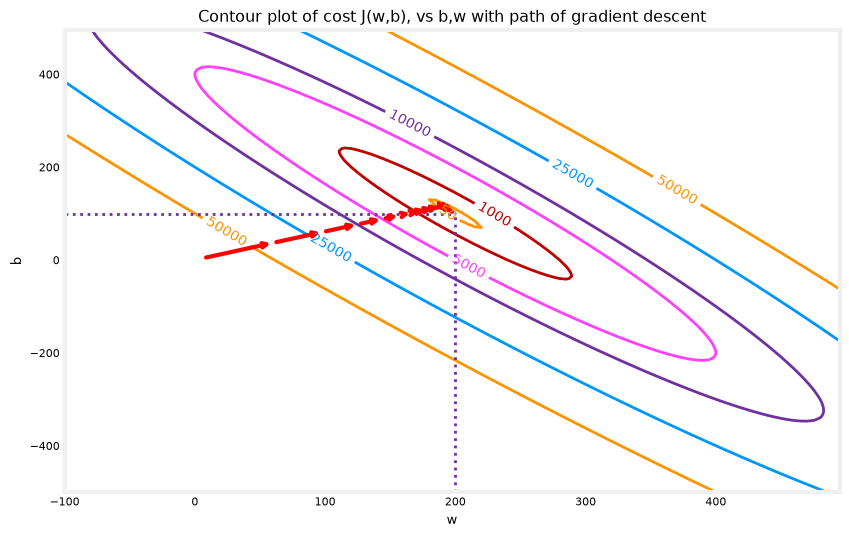

In [11]:
fig, ax = plt.subplots(1, 1, figsize=(10, 6))
plt_contour_wgrad(x_train, y_train, p_hist, ax)
plt.show()

### 5.4. Dự đoán Giá trị Mới (Inference)
Bây giờ bạn có thể dùng mô hình đã huấn luyện xong để dự đoán cho bất kỳ dữ liệu đầu vào nào mới:

In [12]:
x_new = 1.2  # Ví dụ: Nhà rộng 1200 sqft hoặc Dùng 1.2 giờ điều hòa
y_pred = w_final * x_new + b_final
print(f'Với x = {x_new:.1f}, giá trị dự đoán y = {y_pred:.2f} (nghìn USD / nghìn VND)')

Với x = 1.2, giá trị dự đoán y = 340.00 (nghìn USD / nghìn VND)


---
## 🎯 Tóm Tắt Bản Chất Cốt Lõi Tuần 1
1. **Mô hình ($f_{w,b}(x) = wx + b$):** Dự đoán quan hệ đường thẳng giữa $x$ và $y$.
2. **Hàm chi phí ($J(w,b)$):** Đo độ sai số bằng trung bình bình phương khoảng cách giữa điểm thực tế và đường thẳng.
3. **Gradient Descent ($w = w - \alpha \frac{\partial J}{\partial w}$):** Tự động điều chỉnh trọng số bằng cách lấy đạo hàm (đo độ dốc) và bước từng bước nhỏ $\alpha$ về đáy.

🎉 **Chúc mừng bạn đã hoàn thành bài ôn tập Tuần 1!**